# **Exploratory Data Analysis and Data Cleaning**

## **Imports**

In [74]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

## **Loading in Data**

In [75]:
# importing that data that will be used
df = pd.read_csv("ny_real_estate_sold_properties_2026.csv")

In [101]:
df.columns

Index(['type', 'lastSoldPrice', 'sqft', 'stories', 'beds', 'garage', 'city',
       'total_baths'],
      dtype='object')

## **Looking at columns at possibilities of removal**

In [77]:
for col in df.columns:
    print(col)

type
sub_type
text
listPrice
lastSoldPrice
sqft
stories
beds
baths
baths_full
baths_full_calc
garage
zip_code
city
sold_list_ratio
price_per_sqft_sold
price_per_sqft_list
sold_vs_asking
total_baths
has_garage
has_list_price
size_tier
sqft_available


## **Dropping columns**
- have no specific structure
- are not informative or repetitive or
- data leakage

In [78]:
df = df.drop(columns=['sub_type', 'text'])

# Drop columns that leak the final price or are highly incomplete copies
df = df.drop(columns=['sold_list_ratio', 'price_per_sqft_sold', 'price_per_sqft_list', 'sold_vs_asking', 'listPrice', 'size_tier', 'has_list_price', 'sqft_available'])

## **Missing Values**

In [79]:
df.isna().sum()

type                  0
lastSoldPrice         0
sqft                266
stories            3171
beds               1672
baths               258
baths_full         1649
baths_full_calc    1641
garage             5234
zip_code              0
city                  0
total_baths           0
has_garage            0
dtype: int64

### **Baths**

#### Keeping only total_baths and deleting other bath features because has no missing values and the columns are intuitvely colinear

In [80]:
df = df.drop(columns=['baths', 'baths_full', 'baths_full_calc'])

In [81]:
missing_counts = df.isna().sum()
missing_counts[missing_counts > 0]

sqft        266
stories    3171
beds       1672
garage     5234
dtype: int64

### **Garage**

#### Confirms that when has_garage is 0, the garage column is NA. Therefore we can replace those NA in garage with 0's and remove the has_garage column because it's just another less informative way to mention the number of garages

In [82]:
no_garage = df[df['has_garage'] == 0]
print(f"NA count in no_garage for feature 'garage': {no_garage.garage.isna().sum()}")
print(f"Shape of no_garage: {no_garage.shape}")

NA count in no_garage for feature 'garage': 5234
Shape of no_garage: (5234, 10)


In [83]:
df['garage'] = df['garage'].fillna(0)
df = df.drop(columns=['has_garage'])

In [84]:
missing_counts = df.isna().sum()
missing_counts[missing_counts > 0]

sqft        266
stories    3171
beds       1672
dtype: int64

### **Stories**

##### Only keeping stories from 1-5 because the other values are outliers and would skew the data highly

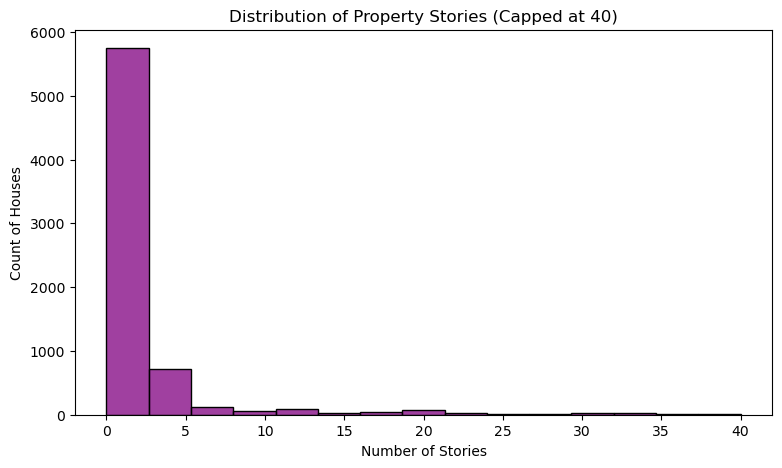

In [85]:
df_cleaned_stories = df[df['stories'] <= 40]

plt.figure(figsize=(9, 5))
# Using histplot with discrete=True groups the counts beautifully
sns.histplot(data=df_cleaned_stories, x='stories', bins=15, kde=False, color='purple')

plt.title('Distribution of Property Stories (Capped at 40)')
plt.xlabel('Number of Stories')
plt.ylabel('Count of Houses')
plt.show()

In [86]:
print(df[df['stories'] <= 5]['stories'].value_counts())

stories
2.0    3794
1.0    1952
3.0     601
4.0      78
5.0      40
0.0       1
Name: count, dtype: int64


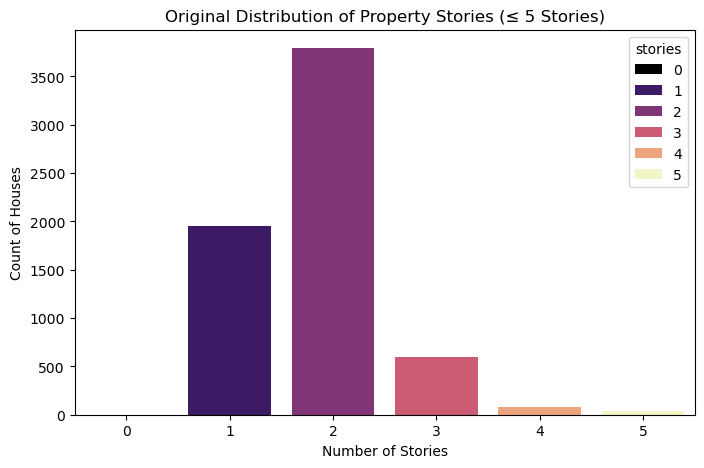

In [87]:
# filtering out the missing values and the outliers for a clearer plot
plot_data = df.dropna(subset=['stories'])
plot_data = plot_data[plot_data['stories'] <= 5]

# for 'stories' to be treated as an integer so the labels look clean (1, 2, 3 instead of 1.0, 2.0)
plot_data['stories'] = plot_data['stories'].astype(int)


plt.figure(figsize=(8, 5))
sns.countplot(data=plot_data, x='stories', hue = 'stories', palette='magma')

plt.title('Original Distribution of Property Stories (≤ 5 Stories)')
plt.xlabel('Number of Stories')
plt.ylabel('Count of Houses')

plt.show()

#### Filling missing values for stories as 1

In [88]:
df['stories'] = df['stories'].fillna(1)
df = df[(df['stories'] <= 5) & (df['stories'] > 0)]

In [89]:
print(df[(df['stories'] <= 5) & (df['stories']> 0)]['stories'].value_counts())

stories
1.0    5123
2.0    3794
3.0     601
4.0      78
5.0      40
Name: count, dtype: int64


In [90]:
missing_counts = df.isna().sum()
missing_counts[missing_counts > 0]

sqft     209
beds    1246
dtype: int64

### **Imputing rest of missing values**

In [91]:
# drop rows where both core conditions are missing to prevent transform deadlock
df = df.dropna(subset=['sqft', 'beds'], how='all')

# impute structural missing values conditionally using Groupby Medians
df['sqft'] = df['sqft'].fillna(
    df.groupby('beds')['sqft'].transform('median')
)

df['beds'] = df['beds'].fillna(
    df.groupby('total_baths')['beds'].transform('median')
).round()

df = df.dropna(subset=['sqft', 'beds'])

In [92]:
missing_counts = df.isna().sum()
missing_counts[missing_counts > 0]

Series([], dtype: int64)

## **Unique Values**

In [93]:
df.dtypes

type              object
lastSoldPrice      int64
sqft             float64
stories          float64
beds             float64
garage           float64
zip_code         float64
city              object
total_baths      float64
dtype: object

In [94]:
for col in df.select_dtypes(include='object'):
    print(f"Value counts for {col}")
    print(df[col].value_counts())
    print()

Value counts for type
type
single_family    6945
multi_family     1336
condo             736
coop              270
townhomes         201
other             146
apartment           1
Name: count, dtype: int64

Value counts for city
city
Brooklyn          577
Rochester         432
Buffalo           395
Staten Island     376
Syracuse          187
                 ... 
Cross River         1
Indian Lake         1
Preston Hollow      1
Esopus              1
Marlboro            1
Name: count, Length: 1093, dtype: int64



### **Dropping singular apartment**

In [95]:
print(f"BEFORE dropping apartment: {df.type.value_counts()}")
# dropping the singular apartment value
df = df[df['type'] != 'apartment']
print(f"\nAFTER dropping apartment: {df.type.value_counts()}")

BEFORE dropping apartment: type
single_family    6945
multi_family     1336
condo             736
coop              270
townhomes         201
other             146
apartment           1
Name: count, dtype: int64

AFTER dropping apartment: type
single_family    6945
multi_family     1336
condo             736
coop              270
townhomes         201
other             146
Name: count, dtype: int64


### **Focusing on the top 9 cities**

In [96]:
threshold = 100

city_counts = df['city'].value_counts()
rare_cities = city_counts[city_counts < threshold].index

df['city'] = df['city'].replace(rare_cities, 'Other')

df = df.drop(columns=['zip_code'])

print(df['city'].value_counts())

city
Other            7237
Brooklyn          577
Rochester         432
Buffalo           395
Staten Island     376
Syracuse          187
Bronx             176
Schenectady       141
Albany            113
Name: count, dtype: int64


In [97]:
# removed the 'Other' rows to focus on the top 9 cities
df = df[df['city'] != 'Other']
print(df['city'].value_counts())

city
Brooklyn         577
Rochester        432
Buffalo          395
Staten Island    376
Syracuse         187
Bronx            176
Schenectady      141
Albany           113
Name: count, dtype: int64
